# RAG vs. No-RAG — Multi-Family LLM Evaluation
## Notebook 05 — Analysis & Visualisation

Computes all metrics and generates figures for the journal paper:

**Metrics:**
- **Exact Match** — lookup questions (account code identification)
- **Semantic Similarity** — describe questions (cosine, cached)
- **Hallucination Rate** — nonexistent account numbers in responses
- **Average Latency** — inference time per query

**Figures:**
1. EM by family and condition
2. Semantic Similarity by family and condition
3. Hallucination Rate by family and condition
4. Cross-lingual gap: Corpus A vs B, nomic vs qwen3 (ablation)
5. Quality/VRAM tradeoff across all models


---
## ⚙️ Configuration

In [21]:
# ── CONFIGURATION — edit only this cell ──────────────────────────────────────

OLLAMA_BASE_URL = "http://100.119.36.113:11434"   # ← set your server IP

DATA_DIR    = "data"
CHROMA_DIR  = f"{DATA_DIR}/chroma_db"
RESULTS_DIR = f"{DATA_DIR}/results"
FIGURES_DIR = f"{DATA_DIR}/figures"

TOP_K       = 5
TEMPERATURE = 0
MAX_TOKENS  = 512

# ── Embedding models ───────────────────────────────────────────────────────────
EMBED_MODELS = {
    "nomic":   "nomic-embed-text",       # English-optimised
    "qwen3s":  "qwen3-embedding:0.6b",   # Multilingual lightweight
    "qwen3m":  "qwen3-embedding:4b",     # Multilingual mid-size
}

# ── ChromaDB collections ───────────────────────────────────────────────────────
COLLECTIONS = {
    "rag_a":        ("corpus_a_nomic",    "nomic"),
    "rag_b_nomic":  ("corpus_b_nomic",    "nomic"),
    "rag_b_qwen3s": ("corpus_b_qwen3s",   "qwen3s"),
    "rag_b_qwen3m": ("corpus_b_qwen3m",   "qwen3m"),
}
# Format: condition → (collection_name, embed_key)

CONDITIONS = ["no_rag", "rag_a", "rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"]

COND_LABELS = {
    "no_rag":        "No RAG",
    "rag_a":         "RAG-A (EN, nomic)",
    "rag_b_nomic":   "RAG-B (HR, nomic)",
    "rag_b_qwen3s":  "RAG-B (HR, qwen3-0.6b)",
    "rag_b_qwen3m":  "RAG-B (HR, qwen3-4b)",
}

# ── Model families ─────────────────────────────────────────────────────────────
MODELS = {
    "Qwen3.5": [
        "qwen3.5:0.8b", "qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b",
        "qwen3.5:27b",  "qwen3.5:35b", "qwen3.5:122b",
    ],
    "Llama": [
        "llama3.2:1b", "llama3.2:3b", "llama3.1:8b", "llama3.3:70b",
    ],
    "Gemma": [
        "gemma3:1b", "gemma3:4b", "gemma3:12b", "gemma3:27b",
    ],
    "Phi": [
        "phi4-mini:latest", "phi4:latest",
    ],
    "DeepSeek": [
        "deepseek-r1:1.5b", "deepseek-r1:7b", "deepseek-r1:14b",
        "deepseek-r1:32b",  "deepseek-r1:70b",
    ],
}
ALL_MODELS = [m for family in MODELS.values() for m in family]

MODEL_PARAMS = {
    "qwen3.5:0.8b":0.8,  "qwen3.5:2b":2,    "qwen3.5:4b":4,
    "qwen3.5:9b":9,      "qwen3.5:27b":27,   "qwen3.5:35b":35,
    "qwen3.5:122b":122,
    "llama3.2:1b":1,     "llama3.2:3b":3,    "llama3.1:8b":8,
    "llama3.3:70b":70,
    "gemma3:1b":1,       "gemma3:4b":4,      "gemma3:12b":12,
    "gemma3:27b":27,
    "phi4-mini:latest":3.8,     "phi4:latest":14,
    "deepseek-r1:1.5b":1.5, "deepseek-r1:7b":7,  "deepseek-r1:14b":14,
    "deepseek-r1:32b":32,   "deepseek-r1:70b":70,
}

import os
for d in [DATA_DIR, CHROMA_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

total_calls = len(ALL_MODELS) * len(CONDITIONS) * 1060
print("✓ Configuration loaded")
print(f"  Models:      {len(ALL_MODELS)}  ({', '.join(MODELS.keys())})")
print(f"  Conditions:  {len(CONDITIONS)}")
print(f"  Questions:   1,060")
print(f"  Total calls: {total_calls:,}")
print()
print("  Embedding models:")
for k, v in EMBED_MODELS.items():
    print(f"    {k:8s}: {v}")


✓ Configuration loaded
  Models:      22  (Qwen3.5, Llama, Gemma, Phi, DeepSeek)
  Conditions:  5
  Questions:   1,060
  Total calls: 116,600

  Embedding models:
    nomic   : nomic-embed-text
    qwen3s  : qwen3-embedding:0.6b
    qwen3m  : qwen3-embedding:4b


---
## 📦 Dependencies

In [22]:
import subprocess
subprocess.run(
    ["pip", "install", "-q", "--root-user-action=ignore",
     "pandas", "matplotlib", "seaborn", "numpy", "requests", "scipy"],
    capture_output=True
)
print("✓ OK")


✓ OK


---
## 📥 Load checkpoints

In [23]:
import json, os, re
import numpy as np
import pandas as pd
import requests
import matplotlib; matplotlib.rcParams["figure.dpi"] = 120
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine
from collections import Counter

sns.set_theme(style="whitegrid", palette="muted")

def checkpoint_path(model, condition):
    safe = model.replace(":","_").replace(".","_")
    return f"{RESULTS_DIR}/{safe}_{condition}.json"

all_results = {}
missing     = []
for model in ALL_MODELS:
    all_results[model] = {}
    for cond in CONDITIONS:
        path = checkpoint_path(model, cond)
        if os.path.exists(path):
            with open(path) as f:
                all_results[model][cond] = json.load(f)
        else:
            missing.append(f"{model}/{cond}")

total_loaded = sum(len(v) for v in all_results.values())
print(f"✓ Loaded {total_loaded} checkpoint files")
if missing:
    print(f"  ⚠ Missing ({len(missing)}): {missing[:5]}{'...' if len(missing)>5 else ''}")
else:
    print("  All checkpoints present")


✓ Loaded 110 checkpoint files
  All checkpoints present


---
## 📐 Compute metrics

In [24]:
# Valid accounts for hallucination detection
with open("accounts.jsonl") as f:
    _raw = [json.loads(l) for l in f if l.strip()]
VALID_ACCOUNTS = set()
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    VALID_ACCOUNTS.add(a.get("account_number",""))

CACHE_PATH = f"{RESULTS_DIR}/sem_sim_cache.json"

def load_cache():
    if os.path.exists(CACHE_PATH):
        with open(CACHE_PATH) as f: return json.load(f)
    return {}

def save_cache(cache):
    with open(CACHE_PATH, "w") as f: json.dump(cache, f, indent=2)

def get_embedding_for_sim(text):
    r = requests.post(
        f"{OLLAMA_BASE_URL}/api/embeddings",
        json={"model": EMBED_MODELS["nomic"], "prompt": text},
        timeout=30
    )
    r.raise_for_status()
    return r.json()["embedding"]

def sem_sim(text1, text2):
    if not text1 or not text2: return 0.0
    try:
        e1 = get_embedding_for_sim(text1)
        e2 = get_embedding_for_sim(text2)
        return round(1 - cosine(e1, e2), 4)
    except: return 0.0

cache = load_cache()
print(f"✓ Semantic similarity cache: {len(cache)} entries")
print(f"  Valid accounts: {len(VALID_ACCOUNTS)}")


✓ Semantic similarity cache: 8690 entries
  Valid accounts: 522


In [34]:
from tqdm import tqdm

def improved_exact_match(response, ground_truth):
    if not response: return False
    if isinstance(ground_truth, str):
        try: ground_truth = json.loads(ground_truth)
        except: return False
    if not isinstance(ground_truth, dict): return False
    expected = str(ground_truth.get("account_number","")).strip()
    if not expected: return False
    found = re.findall(r"(?<![\d])\b(\d{3,4})\b(?![\d])", response)
    return expected in found
'''
def compute_metrics(model, condition, results):
    lookup_em    = []
    describe_sim = []
    hallucinations = []
    latencies    = []

    for r in results:
        q_type   = r["q_type"]
        response = r["response"]
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"],str)                  else r["ground_truth"]
        except: gt = {}
        latencies.append(r["latency_sec"])
        found    = re.findall(r"(?<![\d])\b(\d{3,4})\b(?![\d])", response)
        hallucinations.append(any(n not in VALID_ACCOUNTS for n in found) if found else False)
        if q_type == "lookup":
            lookup_em.append(improved_exact_match(response, gt))
        else:
            gt_text   = gt.get("english_name", gt.get("name",""))
            cache_key = f"{model}|{condition}|{r['question'][:50]}"
            if cache_key not in cache:
                cache[cache_key] = sem_sim(response, gt_text)
                save_cache(cache)
            describe_sim.append(cache[cache_key])

    return {
        "model":        model,
        "condition":    condition,
        "family":       next((f for f, ms in MODELS.items() if model in ms), "?"),
        "params_b":     MODEL_PARAMS.get(model, 0),
        "em_lookup":    round(np.mean(lookup_em)*100, 2)  if lookup_em   else 0,
        "sem_sim_desc": round(np.mean(describe_sim), 4)   if describe_sim else 0,
        "hallucination":round(np.mean(hallucinations)*100, 2),
        "avg_latency":  round(np.mean(latencies), 3),
        "n_lookup":     len(lookup_em),
        "n_describe":   len(describe_sim),
    }
'''


def compute_metrics(model, condition, results):
    lookup_em    = []
    describe_sim = []
    hallucinations = []
    latencies    = []

    for r in results:
        q_type   = r["q_type"]
        response = r["response"]
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except:
            gt = {}

        latencies.append(r["latency_sec"])

        # ── Hallucination — preračunato iz sirovog odgovora ───────────────────
        # Ignoriramo snimljeni r["hallucination"] koji je bio izračunat
        # s nepotpunim VALID_ACCOUNTS (522 konta).
        # Koristimo prošireni VALID_ACCOUNTS (2464 konta iz accounts.jsonl + Corpus B).
        #found = re.findall(r"(?<![\\d])\\b(\\d{3,4})\\b(?![\\d])", response)
        found = re.findall(r"(?<!\d)\b(\d{3,4})\b(?!\d)", response)
        '''
        hall  = any(n not in VALID_ACCOUNTS for n in found) if found else False
        '''
        # Halucinacija samo ako NIJEDAN od pronađenih brojeva nije u VALID_ACCOUNTS
        # Ako model navede barem jedan ispravan konto uz dodatne reference, nije halucinacija
        #NOVOOOOO DODANOOOOO
        hall  = bool(found) and all(n not in VALID_ACCOUNTS for n in found)

        hallucinations.append(hall)

        if q_type == "lookup":
            lookup_em.append(improved_exact_match(response, gt))
        else:
            gt_text   = gt.get("english_name", gt.get("name", ""))
            cache_key = f"{model}|{condition}|{r['question'][:50]}"
            if cache_key not in cache:
                cache[cache_key] = sem_sim(response, gt_text)
                save_cache(cache)
            describe_sim.append(cache[cache_key])

    return {
        "model":        model,
        "condition":    condition,
        "family":       next((f for f, ms in MODELS.items() if model in ms), "?"),
        "params_b":     MODEL_PARAMS.get(model, 0),
        "em_lookup":    round(np.mean(lookup_em)*100, 2)  if lookup_em   else 0,
        "sem_sim_desc": round(np.mean(describe_sim), 4)   if describe_sim else 0,
        "hallucination":round(np.mean(hallucinations)*100, 2),
        "avg_latency":  round(np.mean(latencies), 3),
        "n_lookup":     len(lookup_em),
        "n_describe":   len(describe_sim),
    }

print("Computing metrics (semantic similarity cached after first run)...")
metrics_list = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond in all_results.get(model, {}):
            m = compute_metrics(model, cond, all_results[model][cond])
            metrics_list.append(m)

df = pd.DataFrame(metrics_list)
print(f"\n✓ Metrics computed: {len(df)} rows")

<>:13: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_529/1996715019.py:13: SyntaxWarning: invalid escape sequence '\d'
  '''


Computing metrics (semantic similarity cached after first run)...

✓ Metrics computed: 110 rows


---
## 📊 Summary table

In [35]:
# Pivot tables
for metric, label in [("em_lookup","Exact Match — Lookup (%)"),
                       ("sem_sim_desc","Semantic Similarity — Describe"),
                       ("hallucination","Hallucination Rate (%)")]:
    piv = df.pivot_table(index="model", columns="condition",
                         values=metric, aggfunc="first")
    # Reorder columns
    piv = piv[[c for c in CONDITIONS if c in piv.columns]]
    print(f"\n=== {label} ===")
    print(piv.round(2).to_string())

df.to_csv(f"{RESULTS_DIR}/full_metrics.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/full_metrics.csv")



=== Exact Match — Lookup (%) ===
condition         no_rag  rag_a  rag_b_nomic  rag_b_qwen3s  rag_b_qwen3m
model                                                                   
deepseek-r1:1.5b    0.00  92.64        19.06         36.23         36.42
deepseek-r1:14b     0.19  96.98        28.30         81.89         78.11
deepseek-r1:32b     0.38  97.17        33.21         82.64         82.64
deepseek-r1:70b     0.75  97.55        36.98         85.09         85.47
deepseek-r1:7b      0.19  95.66        33.58         73.21         73.02
gemma3:12b          0.38  97.17        28.87         82.83         83.02
gemma3:1b           0.00  83.77        11.89         48.49         44.91
gemma3:27b          0.19  97.36        36.23         86.04         85.47
gemma3:4b           0.00  96.23        27.17         77.55         75.85
llama3.1:8b         0.00  96.79        23.40         72.08         66.79
llama3.2:1b         0.00  78.68        17.55         28.68         33.96
llama3.2:3b      

---
## 📈 Figure 1 — Exact Match by family and condition

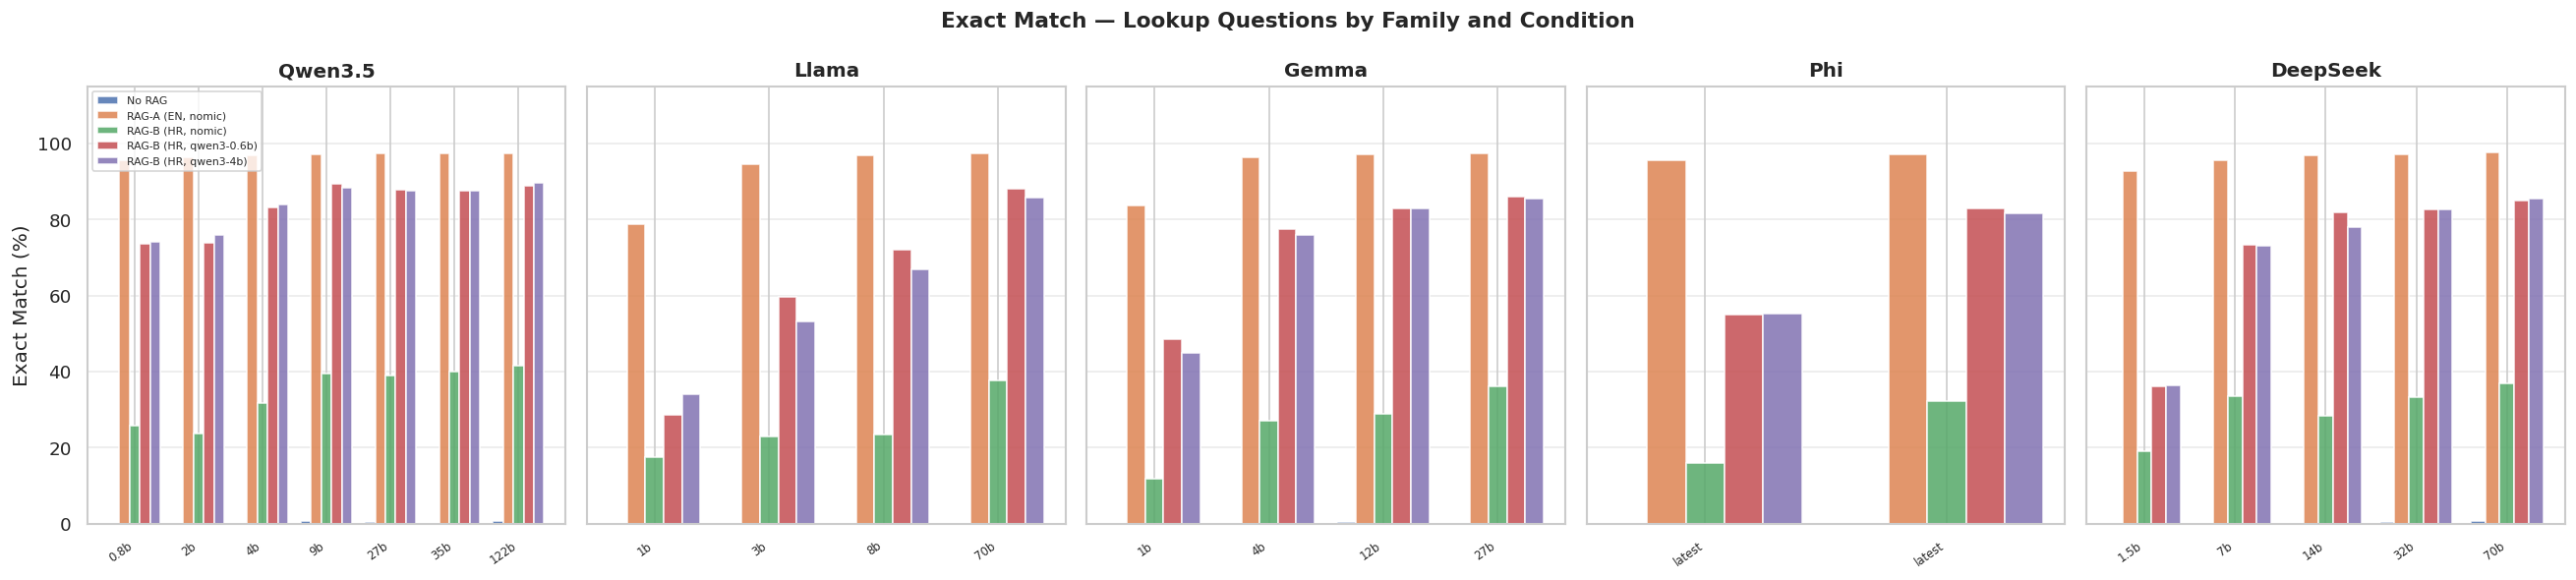

✓ Saved fig1


In [36]:
colors = {
    "no_rag":       "#4C72B0",
    "rag_a":        "#DD8452",
    "rag_b_nomic":  "#55A868",
    "rag_b_qwen3s": "#C44E52",
    "rag_b_qwen3m": "#8172B2",
}

fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Exact Match — Lookup Questions by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    fdf = df[df["family"] == family]
    x   = range(len(family_models))
    w   = 0.16
    for i, cond in enumerate(CONDITIONS):
        vals = []
        for m in family_models:
            v = fdf[(fdf["model"]==m)&(fdf["condition"]==cond)]["em_lookup"].values
            vals.append(v[0] if len(v) else 0)
        ax.bar([xi + i*w for xi in x], vals, w,
               label=COND_LABELS[cond], color=colors[cond], alpha=0.85)
    labels = [m.split(":")[-1] if ":" in m else m for m in family_models]
    ax.set_xticks([xi + 2*w for xi in x])
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=7)
    ax.set_title(family, fontweight="bold")
    ax.set_ylim(0, 115)
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Exact Match (%)")
axes[0].legend(loc="upper left", fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig1_em_by_family.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig1")


---
## 📈 Figure 2 — Semantic Similarity by family and condition

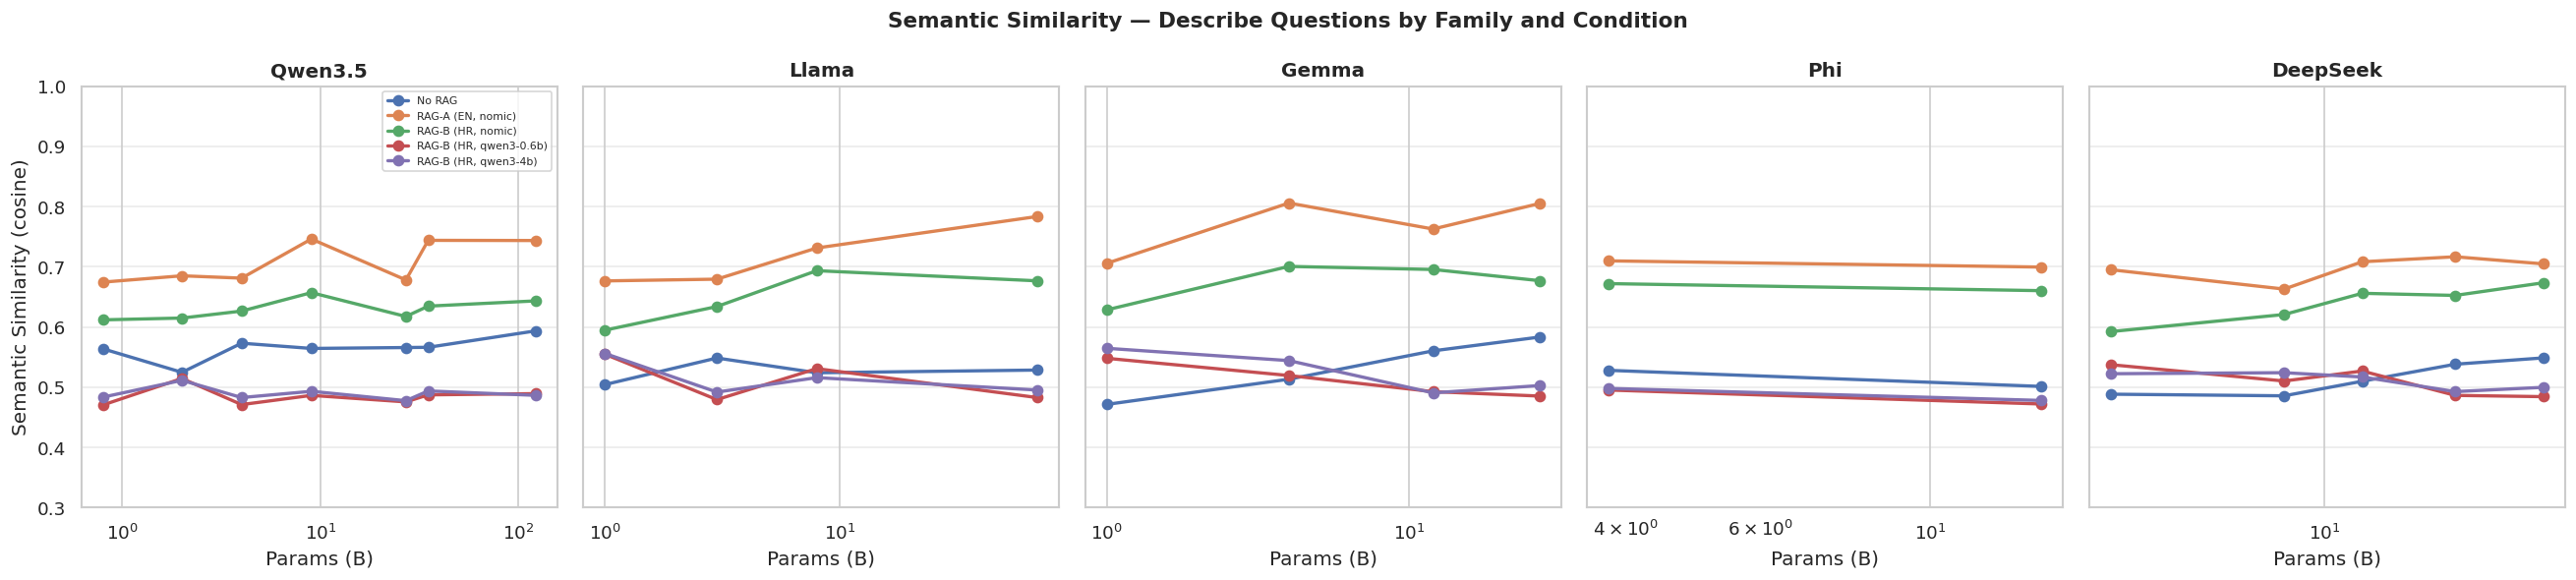

✓ Saved fig2


In [37]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Semantic Similarity — Describe Questions by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    fdf    = df[df["family"] == family]
    params = [MODEL_PARAMS.get(m, 0) for m in family_models]
    for cond in CONDITIONS:
        vals = []
        for m in family_models:
            v = fdf[(fdf["model"]==m)&(fdf["condition"]==cond)]["sem_sim_desc"].values
            vals.append(v[0] if len(v) else 0)
        ax.plot(params, vals, marker="o", label=COND_LABELS[cond],
                color=colors[cond], linewidth=2, markersize=6)
    ax.set_title(family, fontweight="bold")
    ax.set_xlabel("Params (B)")
    ax.set_xscale("log")
    ax.set_ylim(0.3, 1.0)
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Semantic Similarity (cosine)")
axes[0].legend(fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig2_semsim_by_family.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig2")


---
## 📈 Figure 3 — Hallucination Rate

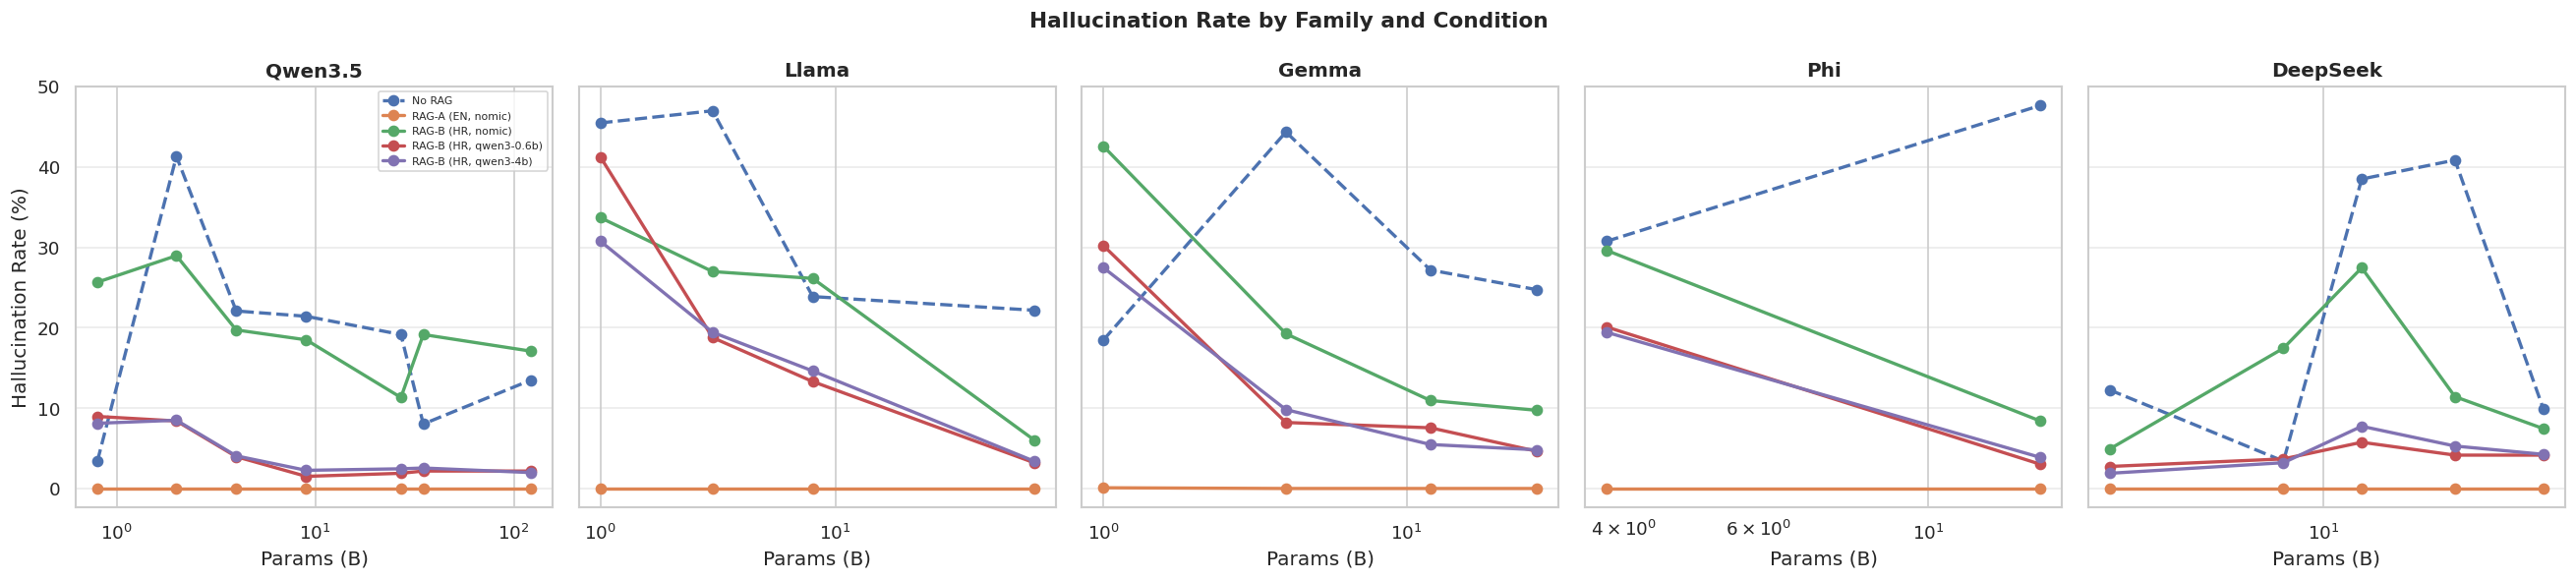

✓ Saved fig3


In [38]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Hallucination Rate by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    fdf    = df[df["family"] == family]
    params = [MODEL_PARAMS.get(m, 0) for m in family_models]
    for cond in CONDITIONS:
        ls  = "--" if cond == "no_rag" else "-"
        vals = []
        for m in family_models:
            v = fdf[(fdf["model"]==m)&(fdf["condition"]==cond)]["hallucination"].values
            vals.append(v[0] if len(v) else 0)
        ax.plot(params, vals, marker="o", label=COND_LABELS[cond],
                color=colors[cond], linewidth=2, markersize=6, linestyle=ls)
    ax.set_title(family, fontweight="bold")
    ax.set_xlabel("Params (B)")
    ax.set_xscale("log")
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Hallucination Rate (%)")
axes[0].legend(fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig3_hallucination.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig3")


---
## 📈 Figure 4 — Ablation: Cross-lingual gap & embedding model effect

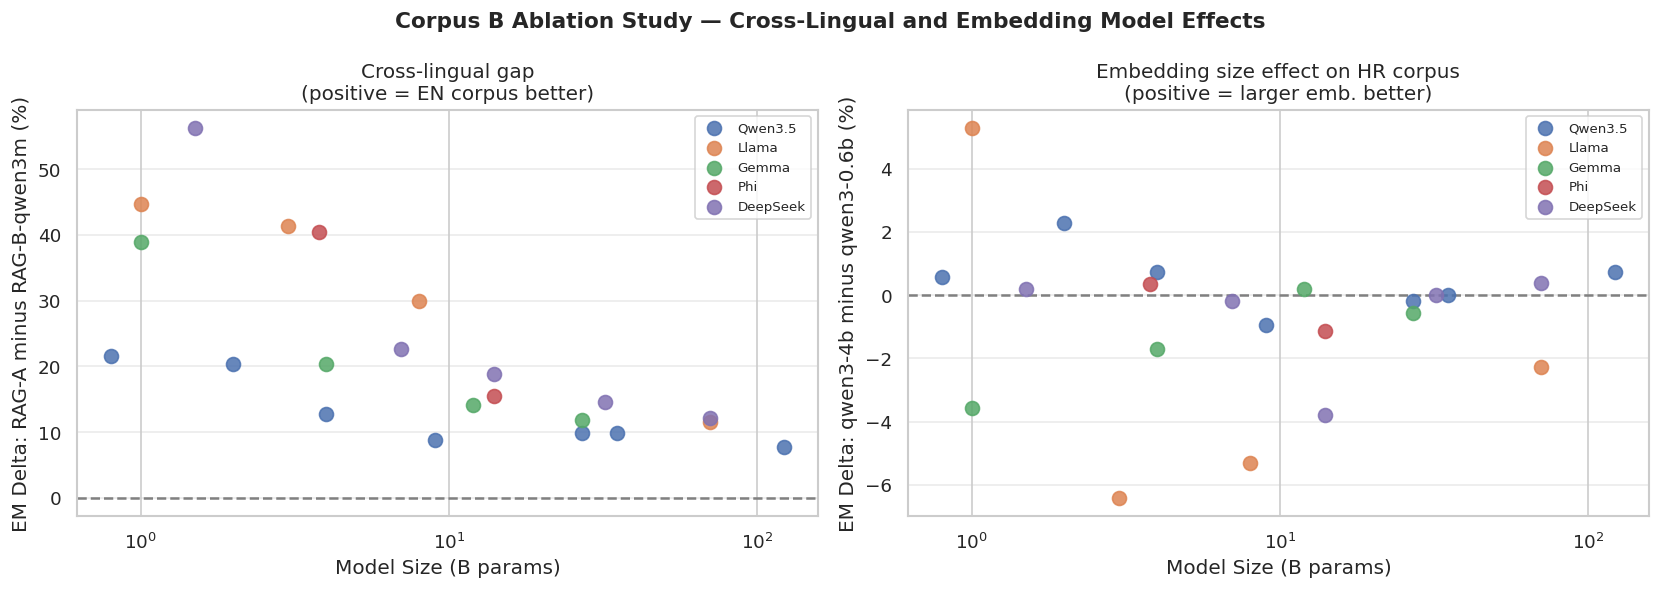

✓ Saved fig4


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Corpus B Ablation Study — Cross-Lingual and Embedding Model Effects",
             fontsize=13, fontweight="bold")
FAMILY_COLORS = {"Qwen3.5":"#4C72B0","Llama":"#DD8452",
                 "Gemma":"#55A868","Phi":"#C44E52","DeepSeek":"#8172B2"}

# Left: RAG-A vs RAG-B-qwen3m (best multilingual)
sub1 = df[df["condition"].isin(["rag_a","rag_b_qwen3m"])].copy()
piv1 = sub1.pivot_table(index=["model","family"], columns="condition",
                         values="em_lookup", aggfunc="first").reset_index()
if "rag_a" in piv1.columns and "rag_b_qwen3m" in piv1.columns:
    piv1["delta"]  = piv1["rag_a"] - piv1["rag_b_qwen3m"]
    piv1["params"] = piv1["model"].map(MODEL_PARAMS)
    for family in MODELS:
        fdf = piv1[piv1["family"]==family]
        axes[0].scatter(fdf["params"], fdf["delta"],
                        label=family, s=70,
                        color=FAMILY_COLORS.get(family,"gray"),
                        alpha=0.85, zorder=3)
    axes[0].axhline(0, color="gray", linestyle="--")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Model Size (B params)")
    axes[0].set_ylabel("EM Delta: RAG-A minus RAG-B-qwen3m (%)")
    axes[0].set_title("Cross-lingual gap\n(positive = EN corpus better)")
    axes[0].legend(fontsize=8)
    axes[0].yaxis.grid(True, alpha=0.4)

# Right: qwen3s vs qwen3m on Corpus B (embedding size effect)
sub2 = df[df["condition"].isin(["rag_b_qwen3s","rag_b_qwen3m"])].copy()
piv2 = sub2.pivot_table(index=["model","family"], columns="condition",
                         values="em_lookup", aggfunc="first").reset_index()
if "rag_b_qwen3s" in piv2.columns and "rag_b_qwen3m" in piv2.columns:
    piv2["delta"]  = piv2["rag_b_qwen3m"] - piv2["rag_b_qwen3s"]
    piv2["params"] = piv2["model"].map(MODEL_PARAMS)
    for family in MODELS:
        fdf = piv2[piv2["family"]==family]
        axes[1].scatter(fdf["params"], fdf["delta"],
                        label=family, s=70,
                        color=FAMILY_COLORS.get(family,"gray"),
                        alpha=0.85, zorder=3)
    axes[1].axhline(0, color="gray", linestyle="--")
    axes[1].set_xscale("log")
    axes[1].set_xlabel("Model Size (B params)")
    axes[1].set_ylabel("EM Delta: qwen3-4b minus qwen3-0.6b (%)")
    axes[1].set_title("Embedding size effect on HR corpus\n(positive = larger emb. better)")
    axes[1].legend(fontsize=8)
    axes[1].yaxis.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig4_ablation_crosslingual.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig4")


---
## 📈 Figure 5 — Quality/VRAM tradeoff

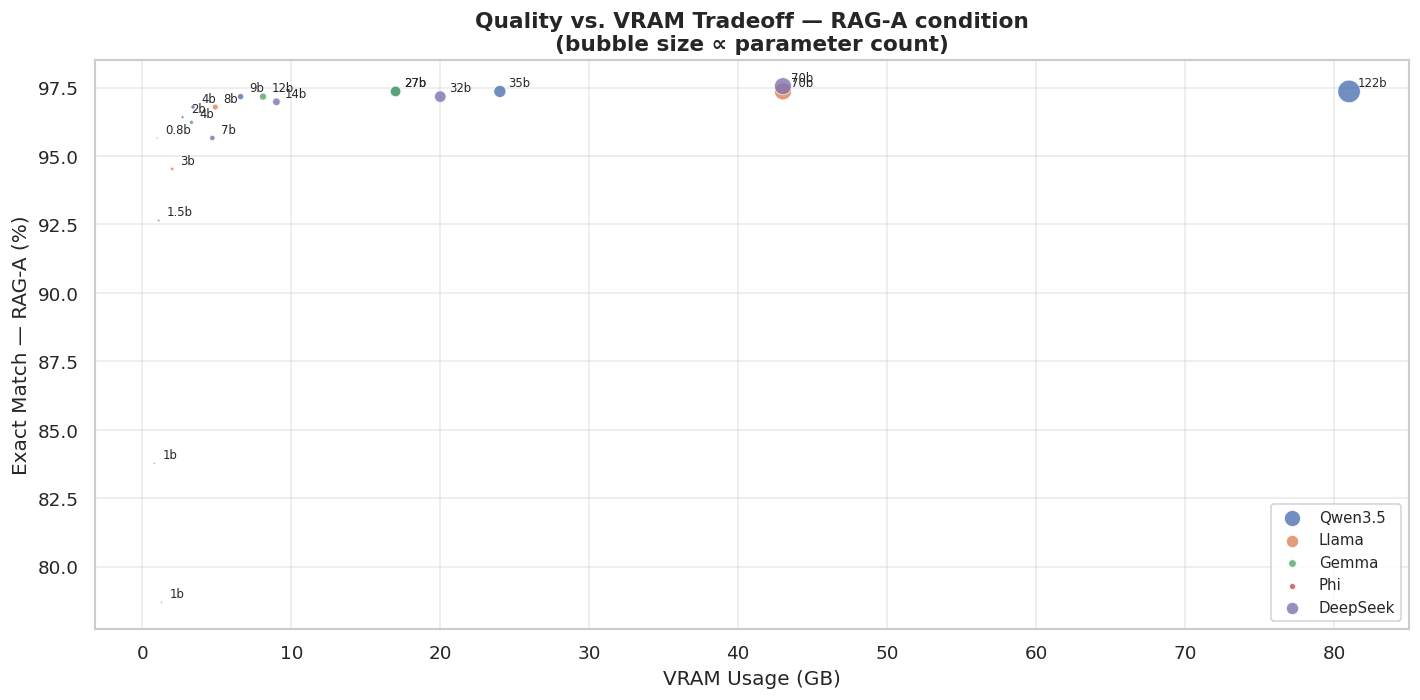

✓ Saved fig5


In [17]:
MODEL_VRAM = {
    "qwen3.5:0.8b":1.0, "qwen3.5:2b":2.7, "qwen3.5:4b":3.4,
    "qwen3.5:9b":6.6,   "qwen3.5:27b":17, "qwen3.5:35b":24,
    "qwen3.5:122b":81,
    "llama3.2:1b":1.3,  "llama3.2:3b":2.0,"llama3.1:8b":4.9,
    "llama3.3:70b":43,
    "gemma3:1b":0.8,    "gemma3:4b":3.3,  "gemma3:12b":8.1,
    "gemma3:27b":17,
    "phi4-mini":2.5,    "phi4":9.1,
    "deepseek-r1:1.5b":1.1,"deepseek-r1:7b":4.7,"deepseek-r1:14b":9.0,
    "deepseek-r1:32b":20,  "deepseek-r1:70b":43,
}

fig, ax = plt.subplots(figsize=(12, 6))
rag_a_df = df[df["condition"]=="rag_a"].copy()
rag_a_df["vram"] = rag_a_df["model"].map(MODEL_VRAM)

for family in MODELS:
    fdf = rag_a_df[rag_a_df["family"]==family]
    ax.scatter(fdf["vram"], fdf["em_lookup"],
               s=fdf["params_b"]*1.5,
               label=family,
               color=FAMILY_COLORS.get(family,"gray"),
               alpha=0.8, edgecolors="white", linewidth=0.5, zorder=3)
    for _, row in fdf.iterrows():
        label = row["model"].split(":")[-1] if ":" in row["model"] else row["model"]
        ax.annotate(label, (row["vram"], row["em_lookup"]),
                    xytext=(5,3), textcoords="offset points", fontsize=7)

ax.set_xlabel("VRAM Usage (GB)", fontsize=12)
ax.set_ylabel("Exact Match — RAG-A (%)", fontsize=12)
ax.set_title("Quality vs. VRAM Tradeoff — RAG-A condition\n"
             "(bubble size ∝ parameter count)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
ax.xaxis.grid(True, alpha=0.4)
ax.yaxis.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig5_quality_vram.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig5")


---
## 📋 Final summary

In [18]:
print("=" * 80)
print("  FINAL RESULTS — RAG vs. No-RAG Multi-Family LLM Evaluation")
print("=" * 80)
header = (f"{'Model':<22} {'Family':<10} "
          f"{'NR':>6} {'A':>6} {'Bn':>7} {'Qs':>7} {'Qm':>7} "
          f"{'NR_H':>6} {'A_H':>5} {'Lat':>6}")
print(header)
print("-" * 80)

cond_map = {
    "no_rag":"NR", "rag_a":"A",
    "rag_b_nomic":"Bn", "rag_b_qwen3s":"Qs", "rag_b_qwen3m":"Qm"
}

for model in ALL_MODELS:
    family = next((f for f, ms in MODELS.items() if model in ms), "?")
    row    = df[df["model"] == model]
    def g(cond, col):
        v = row[row["condition"]==cond][col].values
        return v[0] if len(v) else float("nan")
    print(f"  {model:<20} {family:<10} "
          f"{g('no_rag','em_lookup'):>5.1f}% "
          f"{g('rag_a','em_lookup'):>5.1f}% "
          f"{g('rag_b_nomic','em_lookup'):>6.1f}% "
          f"{g('rag_b_qwen3s','em_lookup'):>6.1f}% "
          f"{g('rag_b_qwen3m','em_lookup'):>6.1f}% "
          f"{g('no_rag','hallucination'):>5.1f}% "
          f"{g('rag_a','hallucination'):>4.1f}% "
          f"{g('no_rag','avg_latency'):>5.2f}s")

print("=" * 80)
print(f"\n✓ All figures: {FIGURES_DIR}/")
print(f"✓ Full CSV:    {RESULTS_DIR}/full_metrics.csv")


  FINAL RESULTS — RAG vs. No-RAG Multi-Family LLM Evaluation
Model                  Family         NR      A      Bn      Qs      Qm   NR_H   A_H    Lat
--------------------------------------------------------------------------------
  qwen3.5:0.8b         Qwen3.5      0.0%  95.7%   25.7%   73.6%   74.2%   3.7%  0.0%  0.49s
  qwen3.5:2b           Qwen3.5      0.0%  96.4%   23.6%   73.8%   76.0%  47.1%  0.4%  0.49s
  qwen3.5:4b           Qwen3.5      0.2%  96.8%   31.7%   83.2%   84.0%  26.1%  0.0%  0.69s
  qwen3.5:9b           Qwen3.5      0.6%  97.2%   39.4%   89.2%   88.3%  28.5%  0.1%  0.80s
  qwen3.5:27b          Qwen3.5      0.4%  97.4%   39.1%   87.7%   87.5%  29.1%  0.0%  2.05s
  qwen3.5:35b          Qwen3.5      0.2%  97.4%   40.0%   87.5%   87.5%  12.1%  0.0%  0.88s
  qwen3.5:122b         Qwen3.5      0.8%  97.4%   41.5%   88.9%   89.6%  28.5%  0.0%  1.23s
  llama3.2:1b          Llama        0.0%  78.7%   17.6%   28.7%   34.0%  45.5%  0.1%  0.26s
  llama3.2:3b          Llama  